In [1]:
%load_ext autoreload
%autoreload 2   

In [2]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning) 

In [3]:
import sys
from pathlib import Path

root = Path.cwd().parent
sys.path.insert(0, str(root))

from collections import OrderedDict
from pathlib import Path

import representation_spaces as rs
from data import GoEmotions
import part1
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools


## Data statistics

#TODO: write dataset description

#TODO: how to handle multi-class data points?

#TODO: merge dev and train for cross-validation?

In [4]:
ds = GoEmotions(drop_multi_labels=True, merge_train_dev=True)
ds.summary

,Total comments,Average n tokens,Median n tokens,Max tokens
train,40856.0,15.36,15.0,47.0
test,4590.0,15.26,15.0,37.0


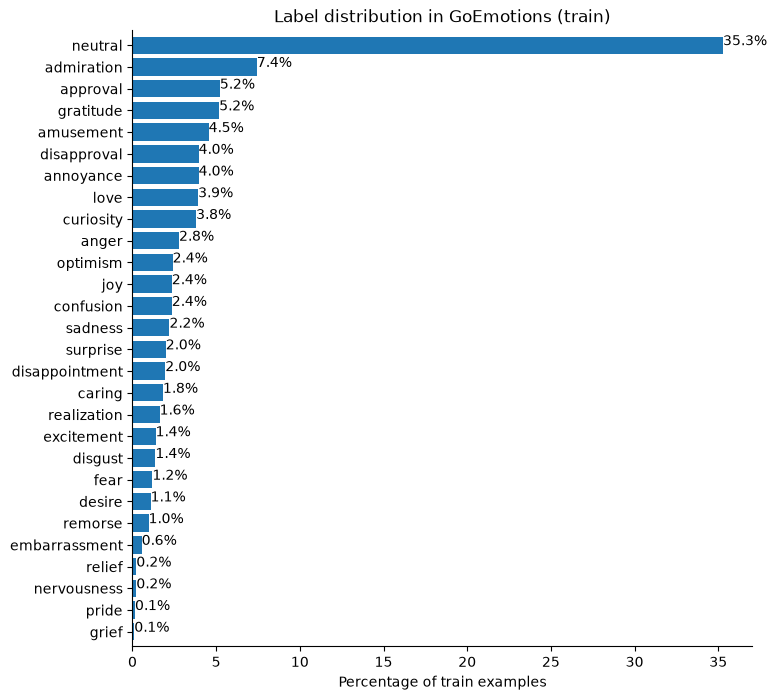

In [5]:
ds.plot_label_dist()

## Experiment

#TODO: description

In [6]:
from tokenizer import WordTokenizer

results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True)

# True: train every config from scratch and save it to results_folder.
# False: load the tokenizer and models already saved in results_folder (no retraining).
TRAIN = False

min_frequency = 1
saved_tokenizers = sorted(results_folder.glob(f"word_tokenizer_vs_*_mf_{min_frequency}.json"))
if not TRAIN and saved_tokenizers:
    tokenizer = WordTokenizer().load(saved_tokenizers[0])
else:
    tokenizer = WordTokenizer().train(ds.train["text"].tolist(), vocab_size=None, min_frequency=min_frequency)
token_indicator_encoder = rs.TokenIndicator(tokenizer)
bag_of_words_encoder = rs.BagOfWords(tokenizer)
tfidf_encoder = rs.Tfidf(tokenizer).fit(ds.train["text"].tolist())

my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []

for seed in my_seeds:
    my_cross_validation_sets.append(
        part1.experiment.cross_validation_split(
            pairs=list(zip(ds.train["text"], ds.train["label"])), 
            k=num_folds,
            seed=seed)
    )

emotions_outcome_space = part1.clslib.NamedClasses(names=ds.emotions)

In [7]:
tokenizer.save(f"{results_folder}/word_tokenizer_vs_{len(tokenizer.get_vocab())}_mf_{min_frequency}.json")

In [8]:
configs = {
    'logistic_indicator-enc': {
        'encoder': token_indicator_encoder,
        'model_option': 'logistic',
        'extra_args':{
            'loglin_args': {
                'max_iter': 1000,
                'tol': 1e-4,
            }
        }
    },
    'mlp_indicator-enc': {
        'encoder': token_indicator_encoder,
        'model_option': 'mlp',
        'extra_args':{
            'smlp_args': {
                'hidden_dim': 128, 
                'num_hidden_layers': 1,
                'dropout': 0.1, 
                'batch_size': 512, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 50,
                'patience': 3,
                'device': 'cuda' if torch.cuda.is_available() else 'cpu',
            }
        }
    },
    'deeper_mlp_indicator-enc': {
        'encoder': token_indicator_encoder,
        'model_option': 'mlp',
        'extra_args':{
            'smlp_args': {
                'hidden_dim': 128, 
                'num_hidden_layers': 2,
                'dropout': 0.1, 
                'batch_size': 512, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 50,
                'patience': 3,
                'device': 'cuda' if torch.cuda.is_available() else 'cpu',
            }
        }
    },
    'logistic_bag-of-words-enc': {
        'encoder': bag_of_words_encoder,
        'model_option': 'logistic',
        'extra_args':{
            'loglin_args': {
                'max_iter': 1000,
                'tol': 1e-4,
            }
        }
    },
    'mlp_bag-of-words-enc': {
        'encoder': bag_of_words_encoder,
        'model_option': 'mlp',
        'extra_args':{
            'smlp_args': {
                'hidden_dim': 128, 
                'num_hidden_layers': 1,
                'dropout': 0.1, 
                'batch_size': 512, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 50,
                'patience': 3,
                'device': 'cuda' if torch.cuda.is_available() else 'cpu',
            }
        }
    },
    'deeper_mlp_bag-of-words-enc': {
        'encoder': bag_of_words_encoder,
        'model_option': 'mlp',
        'extra_args':{
            'smlp_args': {
                'hidden_dim': 128, 
                'num_hidden_layers': 2,
                'dropout': 0.1, 
                'batch_size': 512, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 50,
                'patience': 3,
                'device': 'cuda' if torch.cuda.is_available() else 'cpu',
            }
        }
    },
    'logistic_tfidf-enc': {
        'encoder': tfidf_encoder,
        'model_option': 'logistic',
        'extra_args':{
            'loglin_args': {
                'max_iter': 1000,
                'tol': 1e-4,
            }
        }
    },
    'mlp_tfidf-enc': {
        'encoder': tfidf_encoder,
        'model_option': 'mlp',
        'extra_args':{
            'smlp_args': {
                'hidden_dim': 128, 
                'num_hidden_layers': 1,
                'dropout': 0.1, 
                'batch_size': 512, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 50,
                'patience': 3,
                'device': 'cuda' if torch.cuda.is_available() else 'cpu',
            }
        }
    },
    'deeper_mlp_tfidf-enc': {
        'encoder': tfidf_encoder,
        'model_option': 'mlp',
        'extra_args':{
            'smlp_args': {
                'hidden_dim': 128, 
                'num_hidden_layers': 2,
                'dropout': 0.1, 
                'batch_size': 512, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 50,
                'patience': 3,
                'device': 'cuda' if torch.cuda.is_available() else 'cpu',
            }
        }
    },
}

my_classifiers = OrderedDict()
for config in configs:
    my_classifiers[config] = []
    for run, seed in enumerate(my_seeds):
        run_folder = f"{results_folder}/{config}/seed-{seed}"
        if TRAIN:
            result = part1.experiment.cross_validation_experiment(
                data_splits=my_cross_validation_sets[run],
                outcome_space=emotions_outcome_space,
                encoder=configs[config]['encoder'],
                model_option=configs[config]['model_option'],
                save_to=run_folder,
                **configs[config]['extra_args'],
            )
        else:
            result = part1.experiment.load_cross_validation_experiment(
                data_splits=my_cross_validation_sets[run],
                encoder=configs[config]['encoder'],
                model_option=configs[config]['model_option'],
                load_from=run_folder,
            )
        my_classifiers[config].append(result)

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

/home/julia/Documents/MSc AI/nlp1-student/part1/smlp.py:87: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:916.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

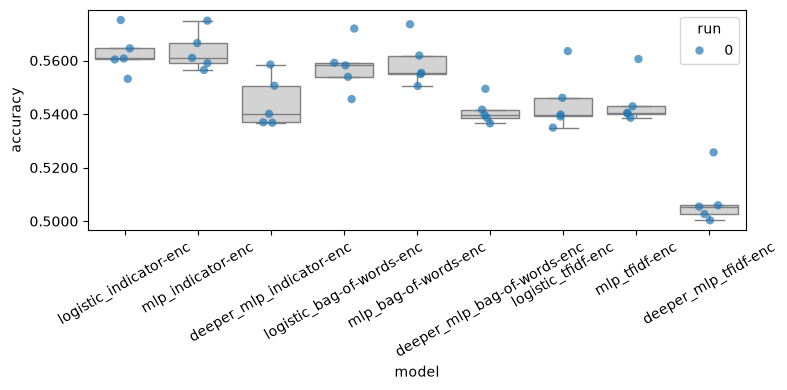

In [9]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))

In [10]:
def get_all_measurements_for(data, sys_name):
    return np.array([list(run_data['accuracies'].values()) for run_data in data[sys_name]])

rope = 0.005
names = list(my_classifiers.keys())          # all nine configs
scores = {n: get_all_measurements_for(my_classifiers, n).flatten() for n in names}

rows = []
p_win = pd.DataFrame(np.nan, index=names, columns=names)   # P(row beats column)

for a, b in itertools.combinations(names, 2):
    posterior = part1.analysis.BenavoliCorrelatedT(
        scores[a],        # shape [num_runs * num_folds]
        scores[b],
        names=[a, b],
    )
    p_a, p_tie, p_b = posterior.probs(rope)
    rows.append({
        "A": a, "B": b,
        "P(A wins)": p_a, "P(Tie)": p_tie, "P(B wins)": p_b,
        "effect_size": posterior.effect_size,
    })
    p_win.loc[a, b] = p_a
    p_win.loc[b, a] = p_b

results_df = pd.DataFrame(rows)
print(results_df.round(4).to_string(index=False))

                          A                           B  P(A wins)  P(Tie)  P(B wins)  effect_size
     logistic_indicator-enc           mlp_indicator-enc     0.0395  0.8793     0.0812       0.3176
     logistic_indicator-enc    deeper_mlp_indicator-enc     0.9967  0.0029     0.0004      -7.1422
     logistic_indicator-enc   logistic_bag-of-words-enc     0.5102  0.4883     0.0015      -3.2495
     logistic_indicator-enc        mlp_bag-of-words-enc     0.1477  0.8513     0.0010      -3.0130
     logistic_indicator-enc deeper_mlp_bag-of-words-enc     0.9950  0.0041     0.0009      -5.9886
     logistic_indicator-enc          logistic_tfidf-enc     0.9865  0.0116     0.0019      -4.7087
     logistic_indicator-enc               mlp_tfidf-enc     0.9953  0.0041     0.0006      -6.4516
     logistic_indicator-enc        deeper_mlp_tfidf-enc     1.0000  0.0000     0.0000     -21.8038
          mlp_indicator-enc    deeper_mlp_indicator-enc     0.9972  0.0025     0.0004      -7.3256
          

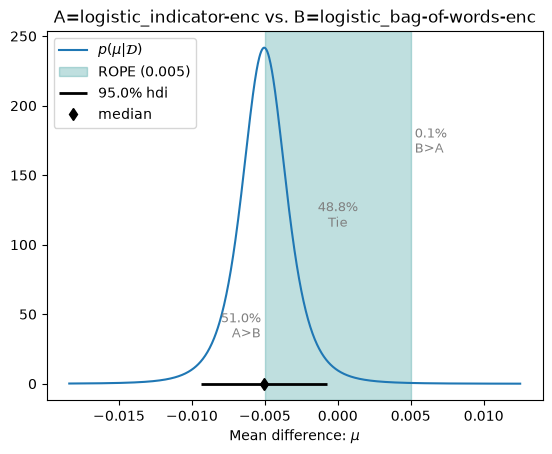

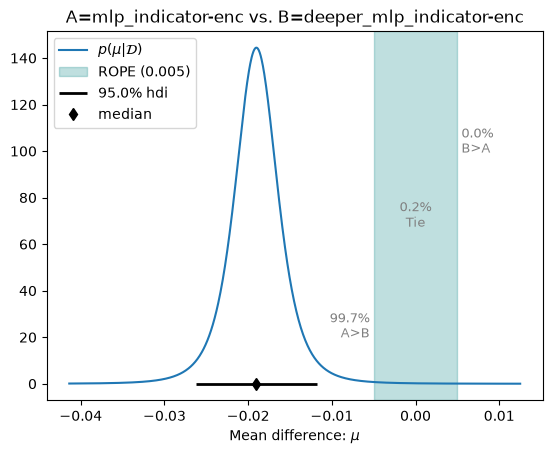

In [11]:
def plot_pair(a, b):
    return part1.analysis.BenavoliCorrelatedT(
        scores[a], scores[b], names=[a, b]
    ).plot(rope)

_ = plot_pair('logistic_indicator-enc', 'logistic_bag-of-words-enc')
_ = plot_pair('mlp_indicator-enc', 'deeper_mlp_indicator-enc')

In [ ]:
from sklearn.metrics import accuracy_score, f1_score
import loglin, smlp        # if this fails, try: from part1 import loglin, smlp

test_texts = ds.test["text"].tolist()
y_test = np.array([int(l) for l in ds.test["label"]])

def fold_probs(config, model_path, texts):
    enc = configs[config]['encoder']
    if configs[config]['model_option'] == 'logistic':
        model = loglin.load(model_path)
        return loglin.predict_probs(texts, model, enc)
    model = smlp.load(model_path)
    return smlp.predict_probs(texts, model, enc, batch_size=512)

test_probs, test_preds, test_rows = {}, {}, []
for name in configs:
    paths = [p for run in my_classifiers[name] for p in run['models'].values()]   # all seeds x folds
    probs = np.mean([fold_probs(name, p, test_texts) for p in paths], axis=0)    # average over fold models
    test_probs[name] = probs
    test_preds[name] = probs.argmax(axis=1)
    test_rows.append({
        "system": name,
        "accuracy": accuracy_score(y_test, test_preds[name]),
        "macro_f1": f1_score(y_test, test_preds[name], average="macro"),
    })

test_df = pd.DataFrame(test_rows).sort_values("accuracy", ascending=False)
test_df.round(4)

,system,accuracy,macro_f1
1,mlp_indicator-enc,0.5712,0.3707
0,logistic_indicator-enc,0.5682,0.3999
4,mlp_bag-of-words-enc,0.5673,0.3671
3,logistic_bag-of-words-enc,0.5664,0.3986
2,deeper_mlp_indicator-enc,0.5601,0.3104
5,deeper_mlp_bag-of-words-enc,0.5536,0.2985
7,mlp_tfidf-enc,0.5536,0.3592
6,logistic_tfidf-enc,0.5442,0.3218
8,deeper_mlp_tfidf-enc,0.5235,0.2397
